# 🎬 BUTACA EMOCIONAL — NLP: Enseñamos a la IA a reconocer sentimientos

## De un comentario escrito a una predicción

**Nivel:** desde cero · **Entorno:** Google Colab (también Jupyter en VS Code) · **Proyecto:** clasificación de reseñas de películas en español.

### El problema
Tenemos miles de críticas de películas. Leerlas una por una es lento. Queremos entrenar un programa que, al recibir **una reseña nueva**, estime si expresa un sentimiento **positivo** o **negativo**.

En el **día 1 (EDA)** estudiamos el conjunto de datos, eliminamos duplicados y creamos gráficos. **Hoy no repetiremos aquellos gráficos:** vamos a convertir textos en números, entrenar un modelo, comprobar cuánto acierta y guardar el resultado para conectarlo con Streamlit.

**Importante:** las etiquetas de este dataset son `positivo` y `negativo`. No incluye una categoría `neutro`, por lo que nuestro modelo **no puede predecir honestamente una clase neutra**.


> **Cómo usar el cuaderno:** ejecuta las celdas de código en orden, con el botón ▶ de cada celda. Los textos Markdown explican qué hace el código que viene después. **No tienes que escribir los resultados a mano:** aparecen al ejecutarlo.

**Nota sobre Google Colab:** también puedes ejecutar este notebook allí. En ese caso debes subir `mood_insights_limpio.csv.gz` al entorno de Colab cada vez que abras una sesión nueva (salvo que lo tengas montado en Google Drive). En VS Code, el archivo permanece guardado en nuestro proyecto.

## 0. Empezamos en VS Code: abrimos nuestro proyecto

Vamos a trabajar con el archivo limpio que **ya hemos exportado desde el EDA**.

### Organización del proyecto

```text
mood-insights/
│
├── data/
│   └── mood_insights_limpio.csv.gz
│
├── notebook/
│   ├── MOOD-INSIGHTS_EDA.ipynb
│   └── MOOD_INSIGHTS_NLP_VSCODE.ipynb
│
└── modelo/
    ├── mood_insights_modelo.joblib
    └── metricas_modelo.json
```

Un notebook combina **celdas Markdown** (explicaciones) y **celdas de código** (Python). En VS Code necesitamos las extensiones **Python** y **Jupyter** para ejecutarlo cómodamente.



## 1. Instalamos las herramientas necesarias

Una **librería** es una caja de herramientas con funciones ya programadas. No tenemos que escribirlo todo desde cero.

- `pandas`: organiza las reseñas en una tabla.
- `scikit-learn`: convierte palabras en números y entrena el modelo.
- `kagglehub`: descarga el dataset desde Kaggle.
- `joblib`: guarda el modelo una vez entrenado.

`%pip install` instala paquetes **en el entorno del notebook**. El signo `%` indica una instrucción especial de Jupyter, no una sentencia normal de Python.

**Ejecuta una sola vez por entorno**, o cuando te indique que falta un paquete.

In [1]:
%pip -q install kagglehub pandas scikit-learn joblib matplotlib

## 2. Importamos las librerías

**Instalar** es poner una herramienta a nuestra disposición; **importar** es decirle a Python que queremos utilizarla.

Ejemplos:
- `import pandas as pd`: damos a Pandas el nombre corto `pd`.
- `from ... import ...`: elegimos una herramienta concreta de una librería.
- `display(...)`: muestra tablas de forma legible en Colab.

No es necesario memorizar todos los nombres: aprenderemos qué hace cada uno cuando lo utilicemos.

In [2]:
# Trabajo con tablas.
import pandas as pd
from pathlib import Path


# Herramientas para crear el modelo y examinar sus predicciones.
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay

# Gráficos y almacenamiento.
import matplotlib.pyplot as plt
import joblib

# Para comprobar ejemplos de texto en Colab.
from IPython.display import display

print("✅ Librerías importadas correctamente.")

✅ Librerías importadas correctamente.


## 3. Localizamos el dataset limpio y comprimido del EDA

El archivo **`mood_insights_limpio.csv.gz`** procede del EDA y está guardado en la carpeta **`data/` de nuestro proyecto**. No descargamos de nuevo el dataset original ni repetimos la limpieza.

Usaremos las columnas `reseña` y `sentimiento` ya preparadas. GZIP comprime el archivo **sin pérdida de datos**; Pandas puede abrirlo directamente.

La siguiente celda contempla dos ubicaciones habituales al trabajar desde VS Code: ejecutar desde la raíz del repositorio (`data/`) o desde una subcarpeta de notebooks (`../data/`).

**En Google Colab:** el notebook no ve automáticamente la carpeta `data/` de tu ordenador o GitHub. Sube el archivo `.csv.gz` mediante el panel **Archivos** de Colab y el código lo encontrará en la carpeta de trabajo. También puedes montar Google Drive si lo guardas allí.

In [ ]:
# Buscamos el dataset comprimido del EDA, sin descomprimirlo previamente.
nombre_csv_limpio = "mood_insights_limpio.csv.gz"

# Si ejecutamos desde la raíz del repositorio, estará en data/.
# Si estamos en la carpeta notebook/, puede encontrarse en ../data/.
# Si lo subimos a Google Colab, estará en la carpeta de trabajo.
rutas_posibles = [
    Path("data") / nombre_csv_limpio,
    Path("..") / "data" / nombre_csv_limpio,
    Path(nombre_csv_limpio),
    Path("/content") / nombre_csv_limpio,  # Ubicación habitual de subidas a Colab.
]
archivo_csv = next((ruta for ruta in rutas_posibles if ruta.is_file()), None)

if archivo_csv is None:
    raise FileNotFoundError(
        f"No se encuentra {nombre_csv_limpio}. Guárdalo en data/ "
        "(VS Code) o súbelo a Archivos en Google Colab. "
        f"Carpeta actual: {Path.cwd()}"
    )

print("✅ Dataset comprimido localizado:", archivo_csv.resolve())

✅ Archivo localizado: /content/mood_insights_limpio.csv


## 4. Leemos directamente el dataset comprimido

El archivo `.csv.gz` ya contiene los textos limpios y las etiquetas. **No hay que extraerlo ni descomprimirlo manualmente.**

- `pd.read_csv(...)` carga los datos en un DataFrame.
- `compression="gzip"` indica a Pandas cómo interpretar el archivo comprimido.
- Comprobamos que existen las dos columnas esperadas: `reseña` y `sentimiento`.

In [ ]:
# Leemos el CSV comprimido exportado por el EDA; Pandas lo descomprime en memoria.
df = pd.read_csv(archivo_csv, compression="gzip")

columnas_necesarias = {"reseña", "sentimiento"}
if not columnas_necesarias.issubset(df.columns):
    raise ValueError(f"Faltan columnas: {columnas_necesarias - set(df.columns)}")

df = df[["reseña", "sentimiento"]].copy()
print("Filas y columnas recibidas del EDA:", df.shape)
display(df.head(3))

Filas y columnas recibidas del EDA: (49599, 2)


,reseña,sentimiento
0,uno de los otros críticos ha mencionado que de...,positivo
1,una pequeña pequeña producción.la técnica de f...,positivo
2,pensé que esta era una manera maravillosa de p...,positivo


## 5. Verificamos el CSV antes de entrenar

La limpieza corresponde al **EDA**. Aquí solo comprobamos que el archivo se ha cargado correctamente; no repetimos el proceso de depuración. Si falla una comprobación, revisamos la exportación del EDA.


In [5]:
print("Valores ausentes por columna:")
print(df.isna().sum())
print("\nFilas repetidas:", df.duplicated().sum())
print("\nEtiquetas encontradas:")
print(df["sentimiento"].value_counts(dropna=False))

if df.empty:
    raise ValueError("El CSV está vacío.")
if df[["reseña", "sentimiento"]].isna().any().any():
    raise ValueError("Hay valores nulos: revisa la limpieza del EDA.")
if df["reseña"].astype(str).str.strip().eq("").any():
    raise ValueError("Hay reseñas vacías: revisa la limpieza del EDA.")
if not df["sentimiento"].isin(["positivo", "negativo"]).all():
    raise ValueError("Hay etiquetas no válidas: revisa la limpieza del EDA.")
if df.duplicated().any():
    raise ValueError("Hay duplicados: revisa la limpieza del EDA.")
if df.groupby("reseña")["sentimiento"].nunique().gt(1).any():
    raise ValueError("Hay etiquetas contradictorias: revisa la limpieza del EDA.")
if df["sentimiento"].value_counts().min() < 2 or df["sentimiento"].nunique() != 2:
    raise ValueError("Se necesitan al menos dos reseñas de cada sentimiento.")
print("\n✅ Archivo validado. Podemos entrenar el modelo.")

Valores ausentes por columna:
reseña         0
sentimiento    0
dtype: int64

Filas repetidas: 0

Etiquetas encontradas:
sentimiento
positivo    24886
negativo    24713
Name: count, dtype: int64

✅ Archivo validado. Podemos entrenar el modelo.


## 6. ¿Cómo puede una máquina leer palabras? Un ejemplo de juguete

Un ordenador no entiende directamente una frase como una persona. Necesitamos convertir las palabras en números.

### ¿Qué hace `CountVectorizer`?

Imagina tres cajas de cartón con palabras escritas: **gusta**, **película** y **aburrida**. Cada vez que aparece una palabra, depositamos una ficha en su caja.

- "me gusta la película" → contamos las palabras que reconoce el programa.
- "la película es aburrida" → repetimos el recuento.

`CountVectorizer` construye automáticamente las cajas (el **vocabulario**) y crea una tabla de recuentos. Esta misma herramienta apareció en nuestro **gráfico 3 del EDA**, pero ahora tendrá una función nueva: preparar las entradas de Machine Learning.

**Vocabulario:** lista de palabras conocidas por el vectorizador. **Matriz:** tabla de números. **Vectorizar:** transformar texto en esa representación numérica.

In [6]:
# Tres frases pequeñas para entender la idea SIN entrenar todavía el modelo real.
frases_ejemplo = [
    "me gusta la película",
    "la película es aburrida",
    "me gusta mucho"
]

# Creamos el contador de palabras (aún no conoce ninguna).
vectorizador_ejemplo = CountVectorizer()

# fit_transform hace dos cosas:
# - fit: aprende qué palabras existen en estas frases.
# - transform: convierte las frases en una tabla de números.
matriz_ejemplo = vectorizador_ejemplo.fit_transform(frases_ejemplo)

# Extraemos las palabras que ha aprendido y mostramos los recuentos.
palabras_ejemplo = vectorizador_ejemplo.get_feature_names_out()
tabla_ejemplo = pd.DataFrame(
    matriz_ejemplo.toarray(),
    columns=palabras_ejemplo,
    index=frases_ejemplo
)

display(tabla_ejemplo)
print("Forma de la matriz (frases, palabras):", matriz_ejemplo.shape)

,aburrida,es,gusta,la,me,mucho,película
me gusta la película,0,0,1,1,1,0,1
la película es aburrida,1,1,0,1,0,0,1
me gusta mucho,0,0,1,0,1,1,0


Forma de la matriz (frases, palabras): (3, 7)


### ¿Qué hemos visto?

- Cada **fila** representa una frase.
- Cada **columna** representa una palabra del vocabulario.
- Un **0** significa que la palabra no aparece en esa frase.
- Un **1** significa que aparece una vez; un **2** significaría dos veces.

**Importante:** este contador es **solo una demostración**. Ahora trabajaremos con las miles de reseñas reales y evitaremos aprender palabras de las reseñas reservadas para el examen.

**Mini comprobación:** observa la columna `película`. ¿Por qué las dos primeras frases tienen un 1 y la tercera un 0?

## 7. ¿Qué es Machine Learning supervisado?

*Machine Learning* significa **aprendizaje automático**: en vez de escribir reglas a mano para cada frase, le enseñamos al programa muchos ejemplos.

En nuestro caso se llama **aprendizaje supervisado**, porque cada reseña viene acompañada de la respuesta correcta.

- `X`: la información que entra al modelo → **textos de las reseñas**.
- `y`: la respuesta que queremos que aprenda → **positivo o negativo**.

Es como preparar un examen escolar: enseñamos con unos ejercicios (**entrenamiento**) y reservamos otros que el alumno no ha visto (**prueba**).

**No debemos enseñar las respuestas del examen durante el entrenamiento.** Si lo hacemos, una buena nota no demostraría que el alumno sabe resolver problemas nuevos.

In [7]:
# X mayúscula: reseñas que verá el clasificador como entrada.
X = df["reseña"]

# y minúscula: sentimiento correcto de cada reseña.
y = df["sentimiento"]

print("Ejemplo de texto (X):", X.iloc[0][:180], "...")
print("Respuesta correspondiente (y):", y.iloc[0])
print("Cantidad de ejemplos:", len(X))

Ejemplo de texto (X): uno de los otros críticos ha mencionado que después de ver solo 1 oz episodio, estará enganchado. tienen razón, ya que esto es exactamente lo que sucedió conmigo. la primera cosa q ...
Respuesta correspondiente (y): positivo
Cantidad de ejemplos: 49599


## 8. Separamos entrenamiento y prueba (80 % / 20 %)

`train_test_split(...)` mezcla y divide las reseñas en dos grupos:

- **80 % para entrenar:** el modelo puede aprender de ellas.
- **20 % para probar:** el modelo no puede aprender de ellas; sirven para medir si generaliza.

### Explicación de los parámetros

- `X, y`: textos y sus respuestas, siempre emparejados.
- `test_size=0.20`: reservamos 20 de cada 100 ejemplos para el examen.
- `random_state=42`: fija la mezcla aleatoria para poder repetir el experimento. **42 no tiene un significado especial**.
- `stratify=y`: intenta conservar una proporción similar de positivos y negativos en ambos grupos.

Los nombres `X_train`, `X_test`, `y_train`, `y_test` indican **entrada/etiqueta** y **entrenamiento/prueba**.

In [8]:
# Separamos las reseñas y sus etiquetas al mismo tiempo.
X_train, X_test, y_train, y_test = train_test_split(
    X,                    # Texto de las reseñas.
    y,                    # Sentimiento conocido.
    test_size=0.20,       # 20 % para el examen.
    random_state=42,      # Siempre la misma división si los datos no cambian.
    stratify=y            # Conserva aproximadamente el equilibrio de sentimientos.
)

print("Reseñas de entrenamiento:", len(X_train))
print("Reseñas de prueba:", len(X_test))
print("Total:", len(X_train) + len(X_test))

print("\nClases en entrenamiento:")
print(y_train.value_counts())

print("\nClases en prueba:")
print(y_test.value_counts())

Reseñas de entrenamiento: 39679
Reseñas de prueba: 9920
Total: 49599

Clases en entrenamiento:
sentimiento
positivo    19909
negativo    19770
Name: count, dtype: int64

Clases en prueba:
sentimiento
positivo    4977
negativo    4943
Name: count, dtype: int64


## 9. ¿Qué modelo utilizaremos? Regresión logística

Aunque su nombre incluye la palabra "regresión", **`LogisticRegression` se utiliza aquí para clasificar**: elegir entre las categorías positivo y negativo.

¿Qué aprende? Busca relaciones estadísticas entre las palabras presentes en las reseñas y las etiquetas conocidas.

Ejemplo simplificado (no son reglas exactas): quizá la palabra "excelente" aparezca más en ejemplos positivos, mientras que "horrible" aparezca más en negativos. El modelo combina muchas señales y toma una decisión.

### ¿Qué es un `Pipeline`?

Es una cadena de montaje con dos estaciones:

**Reseña escrita → `CountVectorizer` (números) → `LogisticRegression` (predicción).**

Gracias al `Pipeline`, cuando entrenemos con `.fit(...)`, **ambas estaciones aprenderán únicamente de `X_train`**. Cuando hagamos `.predict(...)`, el Pipeline transformará los textos nuevos sin tener que contar las palabras manualmente.

**Nota:** en los ejercicios de ejemplo también viste `TfidfVectorizer`. Es otra manera de convertir palabras en números. Para este proyecto inicial elegimos **`CountVectorizer`** por ser más directo y porque el enunciado lo pide expresamente.

In [9]:
# Creamos un Pipeline: una secuencia de pasos.
modelo = Pipeline([
    # Paso 1: crear una matriz con el número de apariciones de las palabras.
    ("contador", CountVectorizer()),

    # Paso 2: aprender a decidir entre positivo y negativo.
    # max_iter=1000 permite más iteraciones si fueran necesarias para converger.
    ("clasificador", LogisticRegression(max_iter=1000, random_state=42))
])

print("Nuestro Pipeline:")
print(modelo)

Nuestro Pipeline:
Pipeline(steps=[('contador', CountVectorizer()),
                ('clasificador',
                 LogisticRegression(max_iter=1000, random_state=42))])


## 10. Entrenamos: aquí empieza el aprendizaje

`fit(X_train, y_train)` significa literalmente **ajustar el modelo usando los ejemplos y sus respuestas**.

En este paso:
1. `CountVectorizer` aprende el vocabulario **solo de las reseñas de entrenamiento**.
2. Transforma esas reseñas en números.
3. `LogisticRegression` aprende patrones asociados a sus sentimientos.

El modelo no aprende reglas morales ni comprende los sentimientos como una persona. Aprende **asociaciones estadísticas** entre el texto y las etiquetas que recibió.

**Esta celda puede tardar algo**, porque hay miles de reseñas y muchas palabras distintas.

In [10]:
# Entrenamos solo con los datos destinados al entrenamiento.
modelo.fit(X_train, y_train)

print("✅ Modelo entrenado. Ya podemos probarlo con reseñas que no ha visto.")

✅ Modelo entrenado. Ya podemos probarlo con reseñas que no ha visto.


### 10.1. Exploramos el vocabulario del modelo

**¿Qué vamos a hacer?** Comprobar cuántos tokens diferentes conoce nuestro modelo y descubrir qué palabras se repiten más en las reseñas de entrenamiento.

**¿Qué es un token?** Es un fragmento de texto que identifica `CountVectorizer`: generalmente una palabra, pero también puede ser un número. El modelo crea una columna para cada token que aprende.

Por ejemplo, si analizamos «película buena» y «película muy buena», la palabra «película» aparece **2 veces**, «buena» **2 veces** y «muy» **1 vez**.

**Lo haremos en cuatro pasos:**

1. Recuperar `CountVectorizer`, que ya se entrenó junto al modelo.
2. Consultar cuántos tokens diferentes hay en su vocabulario.
3. Contar las apariciones de cada token en las reseñas de entrenamiento.
4. Mostrar una tabla con las **10 palabras más repetidas**, ocultando números, tokens de longitud poco práctica y algunas palabras muy comunes como «de», «la» o «que».

**Importante:** ocultar palabras **solo cambia esta tabla**; no elimina palabras del modelo ni modifica cómo clasifica. También conviene recordar que la palabra que más se repite no tiene por qué ser la más útil para distinguir opiniones positivas y negativas.

In [11]:
# Recuperamos el CountVectorizer ya entrenado.
contador = modelo.named_steps["contador"]

# Obtenemos su vocabulario.
vocabulario = contador.get_feature_names_out()

# Mostramos cuántos tokens diferentes conoce.
print("Número de tokens:", len(vocabulario))


# Convertimos las reseñas de entrenamiento en números.
matriz = contador.transform(X_train)

# Contamos cuántas veces aparece cada token.
frecuencias = matriz.sum(axis=0).A1

# Creamos una tabla con las palabras y sus frecuencias.
tabla = pd.DataFrame({
    "Palabra": vocabulario,
    "Frecuencia": frecuencias
})


# Palabras comunes que no queremos mostrar.
stopwords = [
    "el", "la", "los", "las", "un", "una",
    "de", "del", "al", "a", "en", "con",
    "por", "para", "que", "es", "son",
    "y", "o", "se", "su", "sus", "lo"
]

# Conservamos tokens formados solo por letras.
tabla = tabla[tabla["Palabra"].str.isalpha()]

# Conservamos palabras de entre 3 y 15 caracteres.
tabla = tabla[
    tabla["Palabra"].str.len().between(3, 15)
]

# Ocultamos las stopwords de nuestra lista.
tabla = tabla[
    ~tabla["Palabra"].isin(stopwords)
]

# Ordenamos las palabras de mayor a menor frecuencia.
tabla = tabla.sort_values(
    by="Frecuencia",
    ascending=False
)

# Mostramos las diez palabras más repetidas.
print("\nLas diez palabras más frecuentes:")
display(tabla.head(10))


Número de tokens: 158173

Las diez palabras más frecuentes:


,Palabra,Frecuencia
108663,película,120618
55283,esta,64969
30104,como,59032
109557,pero,58448
99806,más,46164
143823,the,42215
56180,está,30229
63611,fue,27712
55550,este,24754
135502,solo,22794


### 10.2. Controlamos el maximo de iteraciones del optimizador

 Nuestro algoritmo es **regresión logística** de Scikit-learn: aquí controlamos el máximo de **iteraciones del optimizador** con `max_iter=1000`.

`n_iter_` nos dice cuántas iteraciones necesitó el entrenamiento real. Si se acerca al máximo y aparece una advertencia de convergencia, habría que revisar el ajuste; no podemos concluir que más iteraciones siempre den mejores predicciones.

In [12]:
# Recuperamos el clasificador dentro de nuestro Pipeline ya entrenado.
clasificador_entrenado = modelo.named_steps["clasificador"]

# n_iter_ contiene el número de iteraciones utilizadas por el optimizador.
print("Iteraciones utilizadas:", clasificador_entrenado.n_iter_)
print("Límite máximo configurado:", clasificador_entrenado.max_iter)

# Comprobación sencilla: ¿llegó al límite máximo?
if max(clasificador_entrenado.n_iter_) >= clasificador_entrenado.max_iter:
    print("Atención: llegó al límite. Conviene revisar la convergencia.")
else:
    print("El algoritmo finalizó antes de alcanzar el máximo de iteraciones.")

Iteraciones utilizadas: [663]
Límite máximo configurado: 1000
El algoritmo finalizó antes de alcanzar el máximo de iteraciones.


## 11. El examen: predecimos las reseñas reservadas

`predict(X_test)` pide al modelo el sentimiento que **cree** que tiene cada texto de prueba. No le damos las etiquetas correctas para que decida: las utilizaremos después para comparar.

Construimos una tabla con:

- **reseña:** comentario original.
- **real:** etiqueta que trae el dataset.
- **predicción:** respuesta del modelo.
- **acierto:** `True` si ambas coinciden; `False` si no.

`==` compara dos valores; aquí **no significa asignar una variable**. El símbolo `=` sí se utiliza para asignar.

In [13]:
# Pedimos predicciones para el conjunto de prueba, nunca visto durante el entrenamiento.
predicciones = modelo.predict(X_test)

# Organizamos textos, respuestas conocidas y predicciones en una tabla.
resultados = pd.DataFrame({
    "reseña": X_test,
    "real": y_test,
    "predicción": predicciones
})

# True significa acierto; False significa error.
resultados["acierto"] = resultados["real"] == resultados["predicción"]

print("Primeros cinco resultados:")
display(resultados.head(5))

Primeros cinco resultados:


,reseña,real,predicción,acierto
38575,realmente espero que los fabricantes de estas ...,negativo,negativo,True
12814,"he pasado un año desplegado en irak, y entre l...",negativo,negativo,True
39513,acabo de ver la versión de dvd de born bad y e...,positivo,negativo,False
21395,"si fuera posible dar estrellas negativas, lo h...",negativo,negativo,True
42309,el gran problema que tuve con esta película fu...,negativo,negativo,True


## 12. Medimos el resultado: exactitud (`accuracy`)

La **exactitud** responde a una pregunta sencilla: **de todos los comentarios del examen, ¿cuántos clasificó correctamente?**

Fórmula:

**Exactitud (%) = (número de predicciones correctas ÷ número total de predicciones) × 100**

Ejemplo con números inventados: si acertamos 8 de 10, la exactitud es 80 %.

En el código, `accuracy_score(y_test, predicciones)` hace esta cuenta con las etiquetas reales y las predichas. `{exactitud:.2%}` muestra un número decimal en formato porcentaje, con dos decimales.

**No confundas** exactitud (`accuracy`) con *precision* (una métrica distinta que veremos después).

In [14]:
# Contamos cuántas respuestas coinciden.
aciertos = resultados["acierto"].sum()
total_prueba = len(resultados)

# Scikit-learn calcula la proporción de aciertos.
exactitud = accuracy_score(y_test, predicciones)

print("Reseñas examinadas:", total_prueba)
print("Predicciones correctas:", aciertos)
print("Predicciones incorrectas:", total_prueba - aciertos)
print(f"Exactitud del modelo: {exactitud:.2%}")

Reseñas examinadas: 9920
Predicciones correctas: 8636
Predicciones incorrectas: 1284
Exactitud del modelo: 87.06%


### 12.1. ¿Es una buena nota? La comparamos con una estrategia ingenua

Imagina un alumno que no lee ningún comentario: siempre responde "positivo" (o la clase que más abunde). Puede acertar muchas veces por pura distribución de clases.

`DummyClassifier(strategy="most_frequent")` es exactamente esa referencia: **no interpreta el texto**, elige siempre la etiqueta más frecuente vista en entrenamiento.

Si nuestro clasificador supera esa referencia, tenemos una señal de que el texto aporta información. **Eso no demuestra que funcione perfectamente fuera de este dataset**.

In [15]:
# Creamos una referencia que no aprende vocabulario ni patrones del texto.
referencia = DummyClassifier(strategy="most_frequent")

# Le damos una tabla de una columna porque el clasificador de referencia espera X en 2D.
referencia.fit(X_train.to_frame(), y_train)

# Predice sin analizar el contenido de las reseñas.
predicciones_referencia = referencia.predict(X_test.to_frame())
exactitud_referencia = accuracy_score(y_test, predicciones_referencia)

print(f"Referencia ingenua: {exactitud_referencia:.2%}")
print(f"Nuestro modelo:    {exactitud:.2%}")
print(f"Diferencia:        {(exactitud - exactitud_referencia) * 100:.2f} puntos porcentuales")

Referencia ingenua: 50.17%
Nuestro modelo:    87.06%
Diferencia:        36.89 puntos porcentuales


## 13. No basta con contar aciertos: matriz de confusión

Una **matriz de confusión** es una tabla de cuatro casillas. Nos cuenta qué clase de aciertos y errores cometió el programa.

En nuestro caso:

| Real ↓ / Predicho → | Negativo | Positivo |
| --- | --- | --- |
| Negativo | Negativo acertado | Negativo confundido con positivo |
| Positivo | Positivo confundido con negativo | Positivo acertado |

**Filas:** lo que realmente decía la etiqueta del dataset. **Columnas:** lo que respondió nuestro modelo.

Las casillas en diagonal son **aciertos**. Las otras dos son **errores**. `confusion_matrix()` realiza los recuentos y `ConfusionMatrixDisplay` dibuja el gráfico.

> Este gráfico pertenece a la **evaluación del modelo del día 2**, no a las conclusiones del EDA del día 1.

,Predicho: negativo,Predicho: positivo
Real: negativo,4270,673
Real: positivo,611,4366


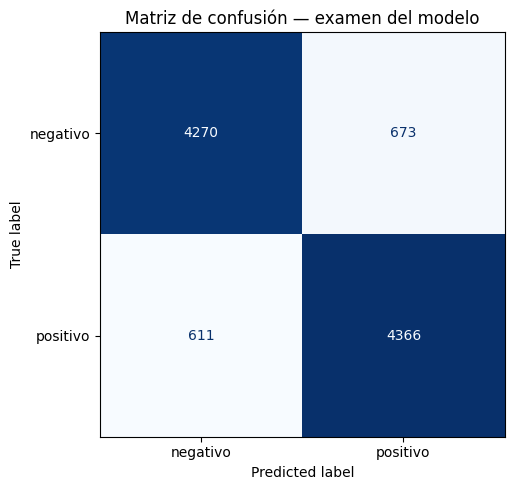

In [16]:
# Fijamos el orden para que las filas y columnas sean fáciles de interpretar.
etiquetas = ["negativo", "positivo"]

# Contamos los cuatro tipos de resultado.
matriz = confusion_matrix(y_test, predicciones, labels=etiquetas)

# Mostramos primero los números en una tabla.
tabla_matriz = pd.DataFrame(
    matriz,
    index=["Real: negativo", "Real: positivo"],
    columns=["Predicho: negativo", "Predicho: positivo"]
)
display(tabla_matriz)

# Dibujamos la MISMA información como una sola figura.
fig, ax = plt.subplots(figsize=(7, 5))
ConfusionMatrixDisplay(confusion_matrix=matriz, display_labels=etiquetas).plot(
    ax=ax, cmap="Blues", colorbar=False, values_format="d"
)
ax.set_title("Matriz de confusión — examen del modelo")
plt.tight_layout()
plt.show()

### 13.1. Otras métricas: `precision`, `recall` y `f1-score`

Estas palabras pueden parecer difíciles. Las leemos como preguntas:

- **Precision** de la clase positiva: *de todas las reseñas que el modelo llamó positivas, ¿cuántas lo eran?*
- **Recall** de la clase positiva: *de todas las reseñas que realmente eran positivas, ¿cuántas encontró?*
- **F1-score:** resume las dos anteriores con una media que penaliza mucho los valores bajos.
- **Support:** cuántas reseñas reales había de cada clase en la prueba.

Lo mismo se calcula para la clase negativa.

**Ejemplo inventado:** si el modelo dice "positivo" 10 veces y acierta 8, su `precision` positiva es 8/10 = 80 %. Si había 20 positivas reales y detectó 8, su `recall` positivo es 8/20 = 40 %. Estas son preguntas distintas.

No hace falta memorizar las fórmulas para interpretar el informe.

In [17]:
# El informe muestra precision, recall, f1-score y support para cada sentimiento.
# zero_division=0 evita un aviso si alguna clase no recibe predicciones.
informe = classification_report(
    y_test,
    predicciones,
    labels=["negativo", "positivo"],
    zero_division=0
)

print("INFORME DE CLASIFICACIÓN")
print(informe)

INFORME DE CLASIFICACIÓN
              precision    recall  f1-score   support

    negativo       0.87      0.86      0.87      4943
    positivo       0.87      0.88      0.87      4977

    accuracy                           0.87      9920
   macro avg       0.87      0.87      0.87      9920
weighted avg       0.87      0.87      0.87      9920



## 14. Aprendemos de los errores

Ningún modelo de este tipo es infalible. Una frase puede ser difícil por **ironía**, **negaciones**, **opiniones mezcladas** o expresiones que aparecen poco en el entrenamiento.

Con `~resultados["acierto"]` elegimos las filas donde `acierto` es `False`. El símbolo `~` invierte valores booleanos: `True` pasa a `False` y viceversa.

Para respetar la lectura, mostramos solo **cinco** errores y recortamos textos demasiado largos en pantalla. **No cambiamos las respuestas reales** para mejorar la nota.

In [18]:
# Nos quedamos con las filas en las que el modelo se equivocó.
errores = resultados.loc[~resultados["acierto"]].copy()

print("Número de errores:", len(errores))

# Mostramos solo los cinco primeros, sin saturar la pantalla.
muestra_errores = errores.head(5).copy()
muestra_errores["reseña"] = muestra_errores["reseña"].str.slice(0, 220) + "…"

display(muestra_errores[["reseña", "real", "predicción"]])

Número de errores: 1284


,reseña,real,predicción
39513,acabo de ver la versión de dvd de born bad y e...,positivo,negativo
24898,he visto esta película en el cine hace muchos ...,negativo,positivo
47933,...éste. lo que vino a mi mente inmediatamente...,positivo,negativo
28508,"desafortunadamente, en casos como estos, hay t...",positivo,negativo
45306,las películas de upa están sorprendentemente b...,negativo,positivo


### Reflexión crítica

Si el modelo falla al clasificar "No me gustó nada", quizá no trate correctamente la negación, o quizá otros términos de la frase pesen más. **No podemos saber la causa exacta de un error solo mirando una frase**: necesitamos investigar más ejemplos.

No hay que utilizar esta clasificación para conocer las emociones o el estado psicológico real de una persona. Nuestro programa **clasifica texto de reseñas**, y sus predicciones son aproximaciones.

## 15. Escribimos opiniones NUEVAS y pedimos predicciones

Ahora vamos a escribir reseñas que **no forman parte intencionalmente del conjunto usado para entrenar**. Como son frases inventadas por nosotros, no tenemos una etiqueta oficial del dataset para medir exactitud.

Con `predict()` obtenemos la clase estimada. También podemos usar `predict_proba()`, que devuelve números entre 0 y 1 utilizados internamente para estimar cada clase.

**Atención:** un valor como 0,90 es una **estimación del modelo**, no una garantía del 90 % ni una medida directa de cómo se siente una persona.

In [19]:
# Puedes editar esta lista y volver a ejecutar la celda.
opiniones_nuevas = [
    "Una película excelente, me emocionó de principio a fin.",
    "Qué aburrimiento, no la recomiendo en absoluto.",
    "La historia empieza bien, pero el final me decepcionó.",
    "No es una mala película, me gustó bastante."
]

# El Pipeline transforma los textos y devuelve una etiqueta por cada frase.
predicciones_nuevas = modelo.predict(opiniones_nuevas)

# Obtenemos también la estimación numérica de cada clase.
probabilidades = modelo.predict_proba(opiniones_nuevas)

# classes_ indica qué clase representa cada columna de probabilidades.
clases = modelo.classes_

# Mostramos texto, resultado y puntuación asociada a la clase elegida.
filas_resultado = []
for texto, prediccion, probabilidades_fila in zip(
    opiniones_nuevas, predicciones_nuevas, probabilidades
):
    indice_clase = list(clases).index(prediccion)
    puntuacion = probabilidades_fila[indice_clase]
    filas_resultado.append({
        "comentario": texto,
        "predicción": prediccion,
        "puntuación del modelo": round(float(puntuacion), 3)
    })

display(pd.DataFrame(filas_resultado))

,comentario,predicción,puntuación del modelo
0,"Una película excelente, me emocionó de princip...",positivo,0.814
1,"Qué aburrimiento, no la recomiendo en absoluto.",negativo,0.819
2,"La historia empieza bien, pero el final me dec...",negativo,0.526
3,"No es una mala película, me gustó bastante.",negativo,0.650


## 16. Guardamos el modelo para reutilizarlo en Streamlit

Cuando entrenamos, el programa construye un modelo que está **en la memoria** de Colab. Si cerramos el entorno y queremos usarlo en una aplicación, necesitamos guardarlo.

`joblib.dump(modelo, "nombre.joblib")` guarda en un archivo **el Pipeline completo**, con el vocabulario y el clasificador aprendidos. Así no tenemos que rehacer la vectorización a mano en Streamlit.

`joblib.load(...)` recupera un modelo desde un archivo. **Por seguridad, solo debemos cargar archivos `.joblib` que hayamos creado nosotros o que procedan de una fuente plenamente confiable:** pueden ejecutar código al cargarse.

El archivo descargado será el puente entre el día 2 y nuestra aplicación web.

In [20]:
# Guardamos el Pipeline completo, NO solo el clasificador.
nombre_archivo_modelo = "mood_insights_modelo.joblib"
joblib.dump(modelo, nombre_archivo_modelo)

print("✅ Modelo guardado en:", nombre_archivo_modelo)
print("Incluye el vectorizador de palabras y el clasificador.")

✅ Modelo guardado en: mood_insights_modelo.joblib
Incluye el vectorizador de palabras y el clasificador.


### 16.1. Descarga opcional desde Google Colab

Si trabajas en **Google Colab**, puedes ejecutar esta celda para descargar el archivo `.joblib` a tu ordenador. En **VS Code**, no hace falta: el archivo queda en la carpeta de trabajo desde la que ejecutas el notebook.

En Colab, `files.download(...)` abre la descarga del archivo guardado. Si el navegador bloquea la descarga, revisa los permisos de descarga de esa página.

In [21]:
# Esta descarga es opcional y solo funciona dentro de Google Colab.
try:
    from google.colab import files
    files.download(nombre_archivo_modelo)
except ImportError:
    print("No estás en Google Colab. El archivo ya se ha guardado localmente.")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 17. Conclusiones del día 2: deben basarse en NUESTROS resultados

A diferencia del EDA, hoy tenemos una **medida de rendimiento del modelo**. La siguiente celda redacta un resumen con los valores calculados durante la ejecución, sin inventar una puntuación.

### Qué hemos hecho
1. Hemos cargado y revisado las reseñas en español.
2. Hemos separado entrenamiento y prueba.
3. Hemos transformado texto en números con `CountVectorizer`.
4. Hemos entrenado `LogisticRegression` dentro de un `Pipeline`.
5. Hemos medido aciertos y errores y comparado con una referencia sencilla.
6. Hemos guardado el Pipeline para continuar en Streamlit.

### Qué NO hemos demostrado

- Que el modelo comprenda emociones humanas.
- Que funcione igual de bien en otros temas, como compras o salud.
- Que detecte sentimientos neutros (no se entrenó con esa categoría).
- Que una puntuación alta en un solo examen garantice el mismo resultado en el mundo real.

**Para el día 3** construiremos la interfaz con Streamlit: un cuadro de texto, un botón y un resultado. El modelo entrenado será el motor de esa aplicación.

In [22]:
# Conclusiones redactadas con los números REALES de esta ejecución.
print("=== CONCLUSIONES DE LA FASE 2 ===")
print(f"Reseñas empleadas: {len(df):,}")
print(f"Entrenamiento: {len(X_train):,} | Prueba: {len(X_test):,}")
print(f"Aciertos en prueba: {aciertos:,} de {total_prueba:,}")
print(f"Exactitud: {exactitud:.2%}")
print(f"Referencia sin leer los textos: {exactitud_referencia:.2%}")
print(f"Errores analizados: {len(errores):,}")
print("Clasificación disponible: positivo o negativo (no neutro).")

if exactitud > exactitud_referencia:
    print("Interpretación: el modelo superó a la referencia básica en esta prueba.")
elif exactitud == exactitud_referencia:
    print("Interpretación: el modelo igualó la referencia básica en esta prueba.")
else:
    print("Interpretación: el modelo quedó por debajo de la referencia básica en esta prueba.")

print("\nSiguiente paso: cargar mood_insights_modelo.joblib desde Streamlit.")

=== CONCLUSIONES DE LA FASE 2 ===
Reseñas empleadas: 49,599
Entrenamiento: 39,679 | Prueba: 9,920
Aciertos en prueba: 8,636 de 9,920
Exactitud: 87.06%
Referencia sin leer los textos: 50.17%
Errores analizados: 1,284
Clasificación disponible: positivo o negativo (no neutro).
Interpretación: el modelo superó a la referencia básica en esta prueba.

Siguiente paso: cargar mood_insights_modelo.joblib desde Streamlit.


## 18. Repaso rápido: ¿puedes explicar lo que hemos construido?

**Pregunta A:** ¿Por qué usamos `CountVectorizer`?  
**Respuesta:** para transformar frases en datos numéricos que pueda utilizar el clasificador.

**Pregunta B:** ¿Por qué guardamos 20 % para prueba?  
**Respuesta:** para examinar el modelo con textos que no utilizó para aprender.

**Pregunta C:** ¿Qué hace `.fit()`?  
**Respuesta:** aprende a partir de los ejemplos de entrenamiento y sus etiquetas.

**Pregunta D:** ¿Qué hace `.predict()`?  
**Respuesta:** recibe nuevos textos y estima su etiqueta.

**Pregunta E:** ¿Por qué algunos errores son útiles?  
**Respuesta:** nos ayudan a identificar limitaciones y posibles mejoras del modelo.

**Pregunta F:** ¿Podemos añadir "neutro" al resultado sin más?  
**Respuesta:** no. Necesitaríamos datos etiquetados como neutros o un criterio adicional bien definido y evaluado.

### Glosario esencial

| Palabra | Significado sencillo |
| --- | --- |
| Dataset | Conjunto organizado de ejemplos. |
| Etiqueta | Respuesta conocida de un ejemplo (`positivo` / `negativo`). |
| Modelo | Programa que ha aprendido patrones de los ejemplos. |
| Vectorizador | Herramienta que convierte las palabras en números. |
| Entrenamiento | Ejemplos que usamos para enseñar al modelo. |
| Prueba | Ejemplos reservados para examinarlo. |
| Predicción | Respuesta estimada por el modelo. |
| Exactitud | Porcentaje total de predicciones correctas. |
| Pipeline | Cadena que une vectorización y clasificación. |

**✅ Entregables del día 2:** notebook explicado, evaluación del clasificador y archivo `mood_insights_modelo.joblib` generado al ejecutarlo. El siguiente paso será la aplicación Streamlit.